# Этап 4. Проверка H1: регрессия Пуассона

**Гипотеза H1:** с ростом температуры выше определённого порога число вызовов растёт. В мета-анализе Xu et al. (2023) это +7 % (5–10 %) вызовов на +5 °C **средней** суточной температуры.

В EDA ты увидела «клюшку» на графике. Но график не доказательство: летом не только жарко, но и туристы, отпуска, длинные дни. Сегодня отделим **эффект температуры** от всего остального и получим число с доверительным интервалом.

**План:**
1. Таблица «день × город».
2. Наивная корреляция и почему ей нельзя верить.
3. Первая модель Пуассона: что значит коэффициент.
4. Модель с контролем сезона, дня недели, праздников.
5. Форма зависимости: где начинается рост?
6. Модель с порогом и ответ на H1.
7. Честные доверительные интервалы.

Правила те же: `# ТВОЙ КОД` пишешь ты, после шага **Вывод:**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

df = pd.read_parquet("../data/processed/daily_borough.parquet")
df.shape

(19630, 17)

## 1. Таблица «день × город»

Начнём с города целиком: так проще, а районы добавим позже.

**Задание:**
1. Оставь только строки **без** COVID. Подсказка: `~` означает «не», то есть `df[~df["is_covid"]]`.
2. Сгруппируй по `date` и собери таблицу `city`:
   - `n_calls` — **сумма** по районам;
   - `tmax` — **среднее** `temperature_2m_max` по районам;
   - `weekday`, `month`, `year`, `is_holiday`, `is_dst_change` — они одинаковые у всех районов в один день, бери `"first"`.

Удобный синтаксис — «именованная агрегация»:
```python
city = (df_clean.groupby("date")
        .agg(n_calls=("n_calls", "sum"),
             tmax=("temperature_2m_max", "mean"),
             ...)
        .reset_index())
```
**Проверка:** должно получиться 3 196 строк (ты считала в итогах этапа 3).

In [2]:
df_clean = df[~df["is_covid"]]
city = (df_clean.groupby("date")
        .agg(n_calls=("n_calls", "sum"),
             tmax=("temperature_2m_max", "mean"),
             weekday = ("weekday", "first"),
             month = ("month", "first"),
             year = ("year", "first") ,
             is_holiday = ("is_holiday", "first"),
             is_dst_change = ("is_dst_change", "first"))
        .reset_index())

## 2. Наивная корреляция

Посчитай корреляцию между `tmax` и `n_calls`: `city[["tmax", "n_calls"]].corr()`.

Корреляция от −1 до 1 показывает, насколько точки ложатся на прямую линию.

**Вопросы:**
- Какое число получилось? Это сильная связь?
- Корреляция говорит «жара **вызывает** рост вызовов»? Придумай хотя бы одну другую причину, почему в тёплые дни вызовов больше.

In [3]:
city[["tmax", "n_calls"]].corr()


,tmax,n_calls
tmax,1.000000,0.411082
n_calls,0.411082,1.000000


**Вывод:** Корреляция 0,41, связь умеренная. Но это не доказывает, что жара вызывает рост вызовов: летом в городе больше туристов и людей на улице (конфаундеры). Чтобы выделить эффект именно температуры, нужно сравнивать дни внутри одного месяца.

## 3. Первая модель Пуассона

**Почему не обычная линейная регрессия?** Число вызовов — это **счётчик**: целое, не бывает отрицательным, и разброс растёт вместе со средним. Для счётчиков есть специальная модель — **регрессия Пуассона**.

**Главное, что нужно понять:** Пуассон моделирует **логарифм** числа вызовов:

$$\log(\text{вызовы}) = b_0 + b_1 \cdot t$$

Поэтому коэффициент читается в **процентах**: +1 °C умножает число вызовов на $e^{b_1}$. Если $b_1 = 0{,}01$, то $e^{0{,}01} \approx 1{,}01$, то есть **+1 % на градус**. Это удобно: эффект одинаков в процентах и для 3 000, и для 5 000 вызовов в день.

**Задание:**
```python
m1 = smf.glm("n_calls ~ tmax", data=city, family=sm.families.Poisson()).fit()
m1.summary()
```
Найди в таблице коэффициент `tmax` и переведи его в проценты: `(np.exp(m1.params["tmax"]) - 1) * 100`.

**Вопрос:** на сколько процентов растут вызовы на +1 °C? А на +5 °C? Подсказка: для +5 °C умножь коэффициент на 5 **до** экспоненты.

In [4]:
m1 = smf.glm("n_calls ~ tmax", data=city, family=sm.families.Poisson()).fit()
m1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:                n_calls   No. Observations:                 3196
Model:                            GLM   Df Residuals:                     3194
Model Family:                 Poisson   Df Model:                            1
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -49813.
Date:                Tue, 03 Nov 2026   Deviance:                       67056.
Time:                        16:26:40   Pearson chi2:                 6.70e+04
No. Iterations:                     4   Pseudo R-squ. (CS):             0.9859
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      8.3007      0.001   1.51e+04      0.000       8.300       8.302
tmax           0.0032   2.75e-05    116.517      0.000       0.003       0.003
==============================================================================
"""

In [5]:
(np.exp(m1.params["tmax"]) - 1) * 100

np.float64(0.32062981557059445)

In [6]:
(np.exp(5 * m1.params["tmax"]) - 1) * 100

np.float64(1.6134624404532838)

**Вывод:**Модель m1 даёт +0,32 % вызовов на +1 °C, то есть +1,6 % на +5 °C. Это меньше, чем в литературе (+7 %), потому что модель проводит одну прямую через весь диапазон температур и сравнивает все холодные дни со всеми жаркими. Зимой вызовов тоже много, и это прижимает наклон. Конфаундеры вроде туристов, наоборот, могут завышать оценку. Поэтому этой цифре пока верить нельзя.

## 4. Убираем «помехи»: контрольные переменные

Модель из шага 3 сравнивает **все** тёплые дни со **всеми** холодными. Но июль отличается от января не только температурой.

Идея: сравнивать дни **внутри одного месяца**. Жаркий июльский день против прохладного июльского дня. Для этого добавляем в формулу контроли:
- `C(month)` — у каждого месяца свой уровень. `C(...)` говорит модели: «это категория, а не число». Иначе модель решит, что декабрь (12) «в 12 раз больше» января (1);
- `C(weekday)` — день недели (ты нашла его в EDA);
- `C(year)` — тренд по годам;
- `is_holiday`, `is_dst_change`.

**Задание:** построй `m2` с формулой `"n_calls ~ tmax + C(month) + C(weekday) + C(year) + is_holiday + is_dst_change"`. Переведи коэффициент `tmax` в проценты.

`summary()` будет длинным, это нормально. Достать один коэффициент: `m2.params["tmax"]`.

**Вопросы:**
- Эффект температуры стал больше или меньше, чем в `m1`? Почему?
- Найди коэффициент `is_holiday`. На сколько процентов меньше вызовов в праздник? Сходится с тем, что ты видела в EDA?

In [7]:
m2 = smf.glm("n_calls ~ tmax + C(month) + C(weekday) + C(year) + is_holiday + is_dst_change",
             data=city, family=sm.families.Poisson()).fit()

In [8]:
(np.exp(5 * m2.params["tmax"]) - 1) * 100   # эффект tmax на +5 °C

np.float64(2.805915436126205)

In [9]:
(np.exp(m2.params["is_holiday[T.True]"]) - 1) * 100

np.float64(-7.269113536743188)

Вывод: Модель m2 сравнивает дни только внутри одного месяца и даёт +0,55 % вызовов на +1 °C, то есть +2,8 % на +5 °C. Это больше, чем в m1: сезонность в сумме занижала эффект сильнее, чем туристы его завышали. Но это всё ещё меньше литературы (+7 %), потому что модель считает каждый градус одинаковым, от −5 °C до +35 °C. Бонус: в праздники вызовов на 7,3 % меньше.

## 5. Форма зависимости: где начинается рост?

`m2` предполагает, что каждый градус добавляет одинаково, и при −5 °C, и при +35 °C. Но в EDA ты видела «клюшку». Проверим форму с контролями.

**Задание:**
1. Разбей температуру на корзины:
   ```python
   city["tbin"] = pd.cut(city["tmax"], bins=[-20, 0, 5, 10, 15, 20, 25, 30, 33, 45]).astype(str)
   ```
2. Посмотри, сколько дней в каждой корзине: `city["tbin"].value_counts().sort_index()`.
3. Построй модель как `m2`, только вместо `tmax` поставь корзину, а сравнивать будем с комфортной погодой 15–20 °C:
   ```
   C(tbin, Treatment(reference="(15, 20]"))
   ```
4. Достань коэффициенты корзин: `m3.params.filter(like="tbin")`, переведи в проценты и нарисуй столбиками.

**Вопросы:**
- С какой температуры вызовы начинают расти?
- Сколько процентов в самой жаркой корзине (33+ °C)?
- Есть ли рост в холод? Сравни с тем, что ты писала в EDA.
- В какой корзине меньше всего дней? Чему там меньше доверять?

In [10]:
city["tbin"] = pd.cut(city["tmax"], bins=[-20, 0, 5, 10, 15, 20, 25, 30, 33, 45]).astype(str)

In [11]:
city["tbin"].value_counts().sort_index()

tbin
(-20, 0]    114
(0, 5]      321
(10, 15]    474
(15, 20]    417
(20, 25]    511
(25, 30]    636
(30, 33]    191
(33, 45]     64
(5, 10]     468
Name: count, dtype: int64

In [12]:
m3 = smf.glm("n_calls ~ C(tbin, Treatment(reference='(15, 20]')) + C(month) + C(weekday) + C(year) + is_holiday + is_dst_change",
             data=city, family=sm.families.Poisson()).fit()

In [13]:
eff = (np.exp(m3.params.filter(like="tbin")) - 1) * 100
eff


C(tbin, Treatment(reference='(15, 20]'))[T.(-20, 0]]    -4.195339
C(tbin, Treatment(reference='(15, 20]'))[T.(0, 5]]      -5.653269
C(tbin, Treatment(reference='(15, 20]'))[T.(10, 15]]    -2.588262
C(tbin, Treatment(reference='(15, 20]'))[T.(20, 25]]     3.734424
C(tbin, Treatment(reference='(15, 20]'))[T.(25, 30]]     8.462605
C(tbin, Treatment(reference='(15, 20]'))[T.(30, 33]]    11.935024
C(tbin, Treatment(reference='(15, 20]'))[T.(33, 45]]    15.865226
C(tbin, Treatment(reference='(15, 20]'))[T.(5, 10]]     -4.478573
dtype: float64

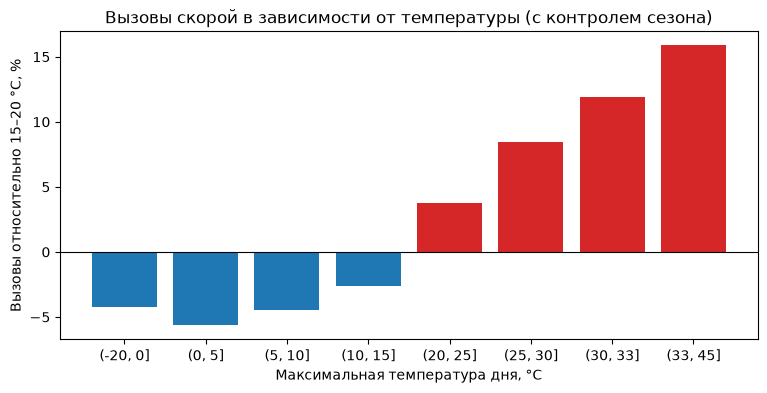

In [14]:
# порядок корзин по температуре
order = ["(-20, 0]", "(0, 5]", "(5, 10]", "(10, 15]",
         "(20, 25]", "(25, 30]", "(30, 33]", "(33, 45]"]

# в названиях коэффициентов оставляем только корзину: "(25, 30]"
eff.index = eff.index.str.extract(r"T\.(.*)\]$")[0] 
eff = eff[order]

# цвет: синий, если вызовов меньше базы, красный, если больше
colors = ["tab:blue" if v < 0 else "tab:red" for v in eff]

plt.figure(figsize=(9, 4))
plt.bar(eff.index, eff.values, color=colors)
plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("Максимальная температура дня, °C")
plt.ylabel("Вызовы относительно 15–20 °C, %")
plt.title("Вызовы скорой в зависимости от температуры (с контролем сезона)")
plt.show()

**Вывод:** Ниже 15 °C число вызовов почти не меняется (от −3 до −6 % относительно 15–20 °C). Рост начинается с 20–25 °C (+3,7 %) и дальше идёт ровно, примерно +4 % на каждые 5 °C. В самые жаркие дни (выше 33 °C) вызовов на 16 % больше, чем в комфортные. Значит, прямая из m2 неверна по форме: ниже 15 °C она видит эффект, которого нет, и поэтому занижает эффект жары.

## 6. Модель с порогом: «хоккейная клюшка»

Клюшку описывают одной новой переменной: **сколько градусов выше порога T**.
```python
city["heat"] = (city["tmax"] - T).clip(lower=0)
```
Если `tmax = 30`, а `T = 25`, то `heat = 5`. Если `tmax = 18`, то `heat = 0`: ниже порога температура «не работает».

**Какой порог выбрать?** Не на глаз, а пусть данные скажут. Для этого есть **AIC**: число, которое оценивает, насколько хорошо модель описывает данные, со штрафом за сложность. **Чем меньше AIC, тем лучше.**

**Задание:**
1. Напиши цикл по порогам `T` от 0 до 30. Для каждого посчитай `heat`, построй модель (как `m2`, но `heat` вместо `tmax`) и запомни `T`, `aic` (атрибут `.aic`) и коэффициент `heat`.
2. Собери результаты в таблицу и нарисуй AIC против T.
3. При каком T минимум AIC? Совпадает ли с тем, что ты увидела в шаге 5?
4. Для лучшего T переведи эффект в проценты **на +5 °C** и сравни с литературой (+7 %).

Подсказка для цикла:
```python
rows = []
for T in range(0, 31):
    ...
    rows.append({"T": T, "aic": m.aic, "coef": m.params["heat"]})
res = pd.DataFrame(rows)
```

Лучший порог: T = 10.0 °C
Эффект: +4.2 % вызовов на каждые +5 °C выше порога


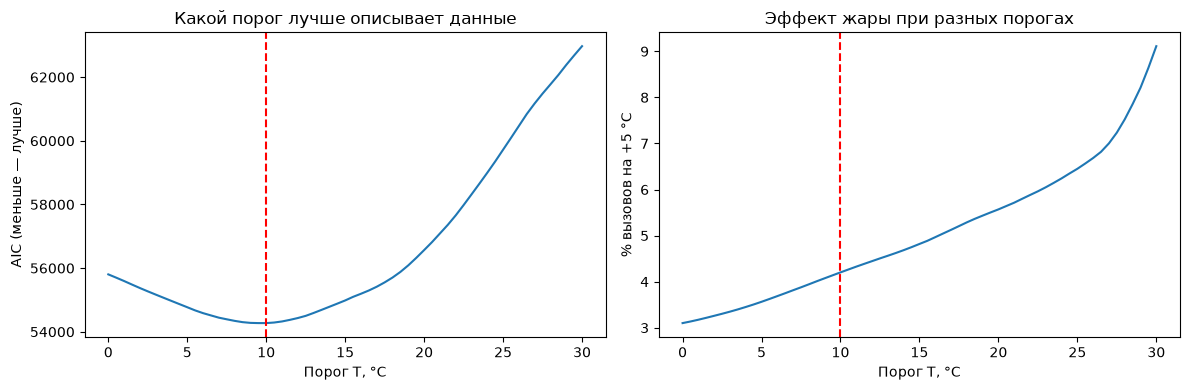

In [15]:
# Контрольные переменные те же, что в m2
controls = "C(month) + C(weekday) + C(year) + is_holiday + is_dst_change"

rows = []
for T in np.arange(0, 30.5, 0.5):          # пороги от 0 до 30 °C с шагом 0,5
    city["heat"] = (city["tmax"] - T).clip(lower=0)
    m = smf.glm("n_calls ~ heat + " + controls,
                data=city, family=sm.families.Poisson()).fit()
    rows.append({"T": T, "aic": m.aic, "coef": m.params["heat"]})

res = pd.DataFrame(rows)
res["pct_5C"] = (np.exp(5 * res["coef"]) - 1) * 100   # эффект на +5 °C в процентах

best = res.loc[res["aic"].idxmin()]
print(f"Лучший порог: T = {best['T']} °C")
print(f"Эффект: +{best['pct_5C']:.1f} % вызовов на каждые +5 °C выше порога")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(res["T"], res["aic"])
ax[0].axvline(best["T"], color="red", linestyle="--")
ax[0].set_xlabel("Порог T, °C"); ax[0].set_ylabel("AIC (меньше — лучше)")
ax[0].set_title("Какой порог лучше описывает данные")
ax[1].plot(res["T"], res["pct_5C"])
ax[1].axvline(best["T"], color="red", linestyle="--")
ax[1].set_xlabel("Порог T, °C"); ax[1].set_ylabel("% вызовов на +5 °C")
ax[1].set_title("Эффект жары при разных порогах")
plt.tight_layout()
plt.show()


**Вывод:** Лучший порог по AIC — **10 °C** (минимум AIC). Это ниже, чем казалось по корзинам (20 °C), но не противоречит им: корзина 10–15 °C (−2,6 %) уже выше, чем 5–10 °C (−4,5 %), то есть рост начинается раньше, просто сначала он слабый. Выше порога каждые +5 °C дают **+4,2 % вызовов**. Это больше, чем у прямой `m2` (+2,8 %), но меньше литературы (+7 %).

Правый график показывает интересную вещь: чем выше порог, тем сильнее эффект (при T = 28 °C уже +7,5 % на 5 °C). Значит, даже выше 10 °C рост не совсем линейный: в сильную жару каждый градус «весит» больше. Модель с одним порогом это усредняет.

## 7. Честные доверительные интервалы

У Пуассона есть строгое допущение: **разброс равен среднему**. Если в среднем 4 000 вызовов, то стандартное отклонение должно быть около $\sqrt{4000} \approx 63$. В жизни разброс обычно больше: бывают события, которые модель не знает (пожар, авария, концерт). Это называется **сверхдисперсия** (overdispersion).

**Проверка:** `m.pearson_chi2 / m.df_resid`. Если около 1, всё хорошо. Если сильно больше 1, модель **слишком уверена в себе**: интервалы получаются узкими, а p-value маленькими незаслуженно.

**Задание:**
1. Посчитай это отношение для лучшей модели из шага 6.
2. Перестрой модель с **устойчивыми** ошибками: `.fit(cov_type="HC0")`. Коэффициент не изменится, изменятся только интервалы.
3. Доверительный интервал: `m.conf_int().loc["heat"]`. Переведи обе границы в проценты на +5 °C.
4. Сравни ширину интервала до и после.

**Вопрос:** почему коэффициент остался прежним, а интервал изменился?

In [16]:
T = best["T"]
city["heat"] = (city["tmax"] - T).clip(lower=0)
model = smf.glm("n_calls ~ heat + " + controls, data=city, family=sm.families.Poisson())

# 1. Проверка сверхдисперсии: должно быть около 1
m_naive = model.fit()
print(f"Сверхдисперсия: {m_naive.pearson_chi2 / m_naive.df_resid:.1f}")

# 2. Три варианта ошибок: коэффициент один и тот же, меняется только ширина интервала
fits = {
    "обычные (Пуассон)": model.fit(),
    "устойчивые HC0":    model.fit(cov_type="HC0"),
    "HAC (соседние дни похожи)": model.fit(cov_type="HAC", cov_kwds={"maxlags": 7}),
}
for name, m in fits.items():
    est = (np.exp(5 * m.params["heat"]) - 1) * 100
    lo, hi = (np.exp(5 * m.conf_int().loc["heat"]) - 1) * 100
    print(f"{name:28s} +{est:.1f} %  [95 % ДИ: {lo:.1f} … {hi:.1f}]")


Сверхдисперсия: 6.9
обычные (Пуассон)            +4.2 %  [95 % ДИ: 4.1 … 4.3]
устойчивые HC0               +4.2 %  [95 % ДИ: 4.0 … 4.4]
HAC (соседние дни похожи)    +4.2 %  [95 % ДИ: 3.9 … 4.5]


**Вывод:** Сверхдисперсия ≈ **6,9**: разброс в 7 раз больше, чем допускает Пуассон, то есть обычные интервалы слишком узкие. С устойчивыми ошибками (HC0) интервал расширился примерно в 2,5 раза: **+4,2 % [4,0 … 4,4 %] на +5 °C**.

Ещё одна проблема: соседние дни похожи друг на друга (если сегодня вызовов много, завтра, скорее всего, тоже). HC0 этого не учитывает, а ошибки HAC учитывают. С ними интервал **[3,9 … 4,5 %]**. Он ещё немного шире, но вывод не меняется: эффект точно больше нуля и лежит около 4 %.

## Итоги: подтвердилась ли H1?

Ответь своими словами в 3–4 предложениях:
1. Есть ли порог? Какой?
2. На сколько процентов растут вызовы на +5 °C выше порога (с интервалом)?
3. Сравни с литературой (+7 % на +5 °C).
4. Чем ответ модели отличается от «клюшки» из EDA и почему?

Это будет первая строка «Результаты» в README.

**Ответ:** 
1. **Порог есть:** около **10 °C** по максимальной температуре дня. Ниже него число вызовов от температуры почти не зависит.
2. Выше порога каждые **+5 °C дают +4,2 % вызовов** (95 % ДИ: 3,9–4,5 %), с учётом сезона, дня недели, года и праздников.
3. Это меньше, чем +7 % на 5 °C в мета-анализе Xu et al. (2023), но там температура средняя за сутки, а у нас максимальная, так что сравнение приблизительное. При этом но в сильную жару эффект больше: по корзинам дни выше 33 °C дают **+16 %** вызовов к комфортным 15–20 °C, а при пороге 28 °C наклон уже ≈ +7,5 % на 5 °C. То есть **H1 подтверждается**, а самый сильный рост приходится именно на жару.
4. «Клюшка» из EDA смешивала жару с сезоном. Модель сравнивает дни внутри одного месяца, поэтому показывает эффект именно температуры, и он оказался меньше, чем выглядело на графике, но статистически надёжным.

**Для README:** *С поправкой на сезон и день недели каждые +5 °C выше 10 °C увеличивают число вызовов скорой в Нью-Йорке на 4,2 % (95 % ДИ 3,9–4,5 %); в дни выше 33 °C вызовов на 16 % больше, чем при 15–20 °C.*